# Practical 6 - Understanding T-Test, ANOVA, Chi-Square

Four different statistical tests this time, all on the teachers' rating dataset: a t-test, an ANOVA, a chi-square test, and a correlation. Each one answers a different kind of question about the data.

Loading the libraries and the dataset first.

In [9]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("TeachingRatings.csv")
df.head()

,rownames,minority,age,gender,credits,beauty,eval,division,native,tenure,students,allstudents,prof
0,1,yes,36,female,more,0.289916,4.3,upper,yes,yes,24,43,1
1,2,no,59,male,more,-0.737732,4.5,upper,yes,yes,17,20,2
2,3,no,51,male,more,-0.571984,3.7,upper,yes,yes,55,55,3
3,4,no,40,female,more,-0.677963,4.3,upper,yes,yes,40,46,4
4,5,no,31,female,more,1.509794,4.4,upper,yes,yes,42,48,5


### Q1. T-Test: Does gender affect teaching evaluation rates?

A t-test compares the means of two groups, which is exactly what we need here — comparing average evaluation scores between male and female instructors.

In [10]:
male_eval = df[df["gender"] == "male"]["eval"]
female_eval = df[df["gender"] == "female"]["eval"]

print("Male mean eval:", round(male_eval.mean(), 3))
print("Female mean eval:", round(female_eval.mean(), 3))

t_stat, p_value = stats.ttest_ind(male_eval, female_eval)
print("\nT statistic:", round(t_stat, 4))
print("P-value:", round(p_value, 6))

Male mean eval: 4.069
Female mean eval: 3.901

T statistic: 3.2499
P-value: 0.001239


**Answer:** Male instructors average about 4.07, female instructors about 3.90. The t-test gives a p-value of about 0.0012, which is well below 0.05, so yes — gender does appear to have a statistically significant effect on evaluation scores here, with male instructors rated slightly higher on average.

### Q2. ANOVA: Does beauty score differ by age?

ANOVA compares means across more than two groups, so first I need to bucket age into a few groups rather than treating it as a raw number.

In [11]:
bins = [0, 40, 50, 60, 100]
labels = ["Under 40", "40-49", "50-59", "60+"]
df["age_group"] = pd.cut(df["age"], bins=bins, labels=labels)

print(df["age_group"].value_counts())

age_group
40-49       146
50-59       145
Under 40    113
60+          59
Name: count, dtype: int64


In [12]:
group_stats = df.groupby("age_group", observed=True)["beauty"].agg(["mean", "std", "count"]).round(3)
print(group_stats)

groups = [df[df["age_group"] == g]["beauty"].dropna() for g in labels]
f_stat, p_value_anova = stats.f_oneway(*groups)

print("\nF statistic:", round(f_stat, 4))
print("P-value:", p_value_anova)

            mean    std  count
age_group                     
Under 40   0.336  0.914    113
40-49     -0.048  0.639    146
50-59     -0.042  0.799    145
60+       -0.420  0.571     59

F statistic: 13.808
P-value: 1.2317171203226513e-08


**Answer:** Beauty scores clearly go down as age increases — averaging around 0.34 for under-40s and dropping to about -0.42 for the 60+ group. The ANOVA gives a very small p-value (way below 0.05), so yes, beauty score does differ significantly by age group. This isn't too surprising since the beauty ratings were given by a panel just from photos, and younger faces tend to get rated as more attractive on average.

### Q3. Chi-Square: Is there an association between tenure and gender?

Chi-square tests whether two categorical variables are related. Here that's tenure (yes/no) and gender (male/female).

In [13]:
tenure_gender_table = pd.crosstab(df["gender"], df["tenure"])
print(tenure_gender_table)

chi2_stat, p_value_chi2, dof, expected = stats.chi2_contingency(tenure_gender_table)
print("\nChi-square statistic:", round(chi2_stat, 4))
print("P-value:", round(p_value_chi2, 4))
print("Degrees of freedom:", dof)

tenure  no  yes
gender         
female  50  145
male    52  216

Chi-square statistic: 2.2068
P-value: 0.1374
Degrees of freedom: 1


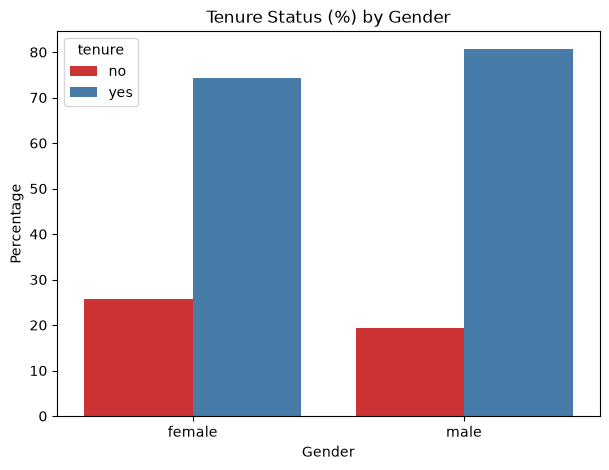

In [14]:
tenure_pct = pd.crosstab(df["gender"], df["tenure"], normalize="index") * 100
tenure_pct_plot = tenure_pct.reset_index().melt(id_vars="gender", var_name="tenure", value_name="percent")

plt.figure(figsize=(7,5))
sns.barplot(data=tenure_pct_plot, x="gender", y="percent", hue="tenure", palette="Set1")
plt.title("Tenure Status (%) by Gender")
plt.xlabel("Gender")
plt.ylabel("Percentage")
plt.show()

**Answer:** The p-value here is about 0.137, which is above 0.05, so we don't have enough evidence to say tenure and gender are associated. Even though male instructors have a slightly higher tenure rate in the raw numbers (about 80.6% vs 74.4% for females), the chi-square test says this gap is small enough that it could just be due to random chance in this sample.

### Q4. Correlation: Is teaching evaluation score correlated with beauty score?

A correlation tells us how strongly two continuous variables move together. Let's check that between eval and beauty, and visualize it with a scatter plot.

In [15]:
correlation, p_value_corr = stats.pearsonr(df["eval"], df["beauty"])
print("Correlation coefficient:", round(correlation, 4))
print("P-value:", p_value_corr)

Correlation coefficient: 0.189
P-value: 4.247115507785999e-05


**Answer:** The correlation is about 0.19, which is a weak but statistically significant positive relationship (p-value is tiny, well under 0.05). So there is some tendency for instructors with higher beauty scores to also get higher evaluation scores, but the relationship is pretty weak — beauty clearly isn't the main driver of how students rate a course.

## Conclusion

Across all four tests, gender showed up as a real factor in evaluation scores (t-test), and beauty score dropped off significantly with age (ANOVA) — both statistically significant results. Tenure and gender, on the other hand, didn't show a significant association (chi-square), so the small gap in tenure rates between genders is likely just noise. Lastly, beauty and evaluation score are weakly but genuinely correlated (correlation test) — better-looking instructors get slightly higher ratings on average, but the effect is small, so plenty of other things must matter more for how students actually rate a course.